# Test sur une image personnelle (`Module 1` + `Module 2`)

Ce notebook vous permet de tester votre modèle entraîné (`best.pt`) sur **une image de votre choix** (prise chez vous ou stockée sur votre PC), avec des blocs séparés :
- **Bloc 1** : choisir le chemin de votre image (`MON_IMAGE`) et charger automatiquement le dernier `best.pt`.
- **Bloc 2** : exécuter la segmentation (`YOLOv8-seg`), afficher la liste des éléments détectés et visualiser l'image segmentée.
- **Bloc 3** : extraire la géométrie (`Module 2` : squelette, longueur en pixels, extrémités et intersections) et afficher la visualisation complète.

## Bloc 1 — Chemin de votre image et chargement de `best.pt`

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.morphology import skeletonize
from ultralytics import YOLO

# Mettez ici le chemin complet de votre image (ex. r"C:\Users\...\Desktop\mon_cable.jpg")
MON_IMAGE = Path(r"D:\S5\Projet_d_expertise\projet\data\processed\Harness comportement detection.v1i.yolov8\test\images\Cable_MHEV_NC11_2_jpg.rf.32eca55c054dabaed70b5ec34c4bb346.jpg").resolve()

# Si MON_IMAGE pointe vers un dossier, on prend automatiquement la première image trouvée
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
if MON_IMAGE.is_dir():
    imgs = sorted([p for p in MON_IMAGE.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS])
    if not imgs:
        raise FileNotFoundError(f"Aucune image trouvée dans le dossier : {MON_IMAGE}")
    MON_IMAGE = imgs[0]
    print(f"Dossier détecté : sélection automatique de {MON_IMAGE}")

if not MON_IMAGE.exists():
    raise FileNotFoundError(f"Image introuvable : {MON_IMAGE}. Vérifiez le chemin dans MON_IMAGE.")

BEST_WEIGHTS = Path(r"D:\S5\Projet_d_expertise\projet\models\wiring_harness_connectors_seg\weights\best.pt").resolve()
if not BEST_WEIGHTS.exists():
    candidates = sorted(Path(r"D:\S5\Projet_d_expertise\projet\models").glob("**/best.pt"), key=lambda p: p.stat().st_mtime, reverse=True)
    if candidates:
        BEST_WEIGHTS = candidates[0].resolve()
        print(f"best.pt trouvé automatiquement : {BEST_WEIGHTS}")
    else:
        raise FileNotFoundError("Aucun fichier best.pt trouvé.")

model = YOLO(str(BEST_WEIGHTS))
img_bgr = cv2.imread(str(MON_IMAGE))
if img_bgr is None:
    raise ValueError(f"Impossible de charger l'image : {MON_IMAGE}")

print(f"Image prête : {MON_IMAGE.name} (dimensions : {img_bgr.shape[1]}x{img_bgr.shape[0]})")
print(f"Modèle chargé : {BEST_WEIGHTS}")

c:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
c:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
c:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


best.pt trouvé automatiquement : D:\S5\Projet_d_expertise\projet\models\01_detection_et_segmentation\ep91_100\weights\best.pt
Image prête : Cable_MHEV_NC11_2_jpg.rf.32eca55c054dabaed70b5ec34c4bb346.jpg (dimensions : 640x640)
Modèle chargé : D:\S5\Projet_d_expertise\projet\models\01_detection_et_segmentation\ep91_100\weights\best.pt


## Bloc 2 — Détection & Segmentation (`Module 1`)

Nombre d'éléments détectés : 21


,id,class_name,conf,bbox_xyxy,mask_pixels
0,0,connector,0.806,"[492.0, 19.8, 520.0, 60.5]",1135
1,1,clip,0.754,"[303.5, 63.7, 315.4, 113.5]",741
2,2,clip,0.716,"[383.7, 247.4, 409.2, 301.5]",1116
3,3,connector,0.672,"[425.2, 419.3, 451.4, 463.8]",1138
4,4,connector,0.667,"[197.2, 411.2, 233.7, 454.8]",1720
5,5,label,0.635,"[540.6, 260.5, 580.0, 348.9]",3538
6,6,cable,0.580,"[355.5, 75.9, 369.1, 132.2]",848
7,7,clip,0.522,"[382.7, 262.8, 409.2, 300.5]",914
8,8,cable,0.419,"[356.8, 536.4, 375.2, 578.4]",368
9,9,connector,0.361,"[541.1, 260.4, 580.9, 348.6]",3492


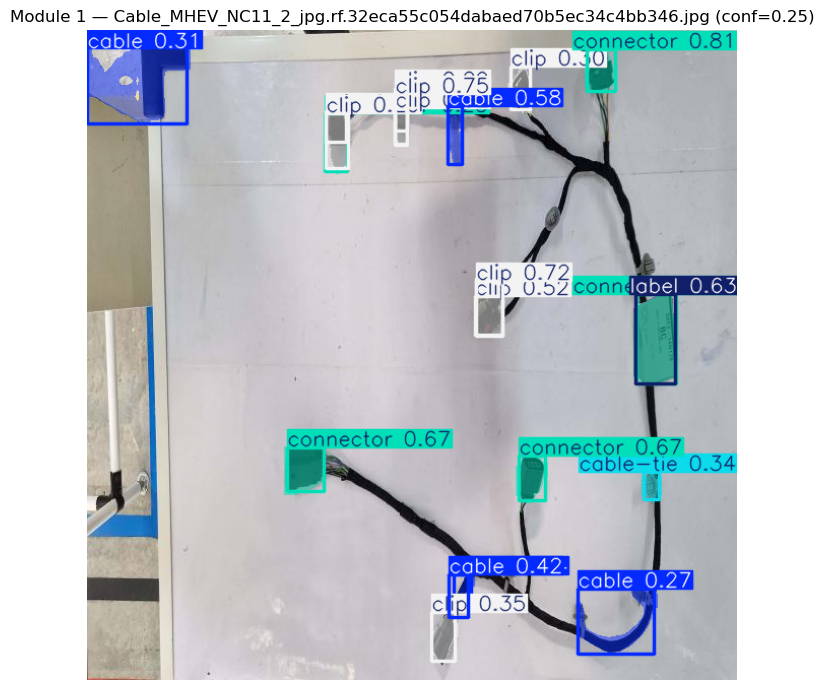

In [2]:
CONF_THRESHOLD = 0.25  # Vous pouvez baisser (ex. 0.15) ou augmenter (ex. 0.40) selon votre image
IMG_SIZE = 640

h, w = img_bgr.shape[:2]
res = model.predict(source=str(MON_IMAGE), conf=CONF_THRESHOLD, imgsz=IMG_SIZE, verbose=False)[0]

detections = []
if res.boxes is not None and len(res.boxes) > 0:
    cls_ids = res.boxes.cls.cpu().numpy().astype(int)
    confs = res.boxes.conf.cpu().numpy()
    boxes_xyxy = res.boxes.xyxy.cpu().numpy()
    masks_np = res.masks.data.cpu().numpy() if res.masks is not None else None

    for idx in range(len(cls_ids)):
        cid = int(cls_ids[idx])
        cname = model.names.get(cid, str(cid))
        x1, y1, x2, y2 = [float(v) for v in boxes_xyxy[idx]]

        if masks_np is not None and idx < len(masks_np):
            mask_u8 = cv2.resize(
                (masks_np[idx] > 0.5).astype(np.uint8) * 255,
                (w, h),
                interpolation=cv2.INTER_NEAREST,
            )
        else:
            mask_u8 = np.zeros((h, w), dtype=np.uint8)

        detections.append({
            "id": idx,
            "class_name": cname,
            "conf": round(float(confs[idx]), 3),
            "bbox_xyxy": [round(v, 1) for v in [x1, y1, x2, y2]],
            "mask_pixels": int((mask_u8 > 0).sum()),
            "mask_u8": mask_u8,
        })

print(f"Nombre d'éléments détectés : {len(detections)}")
if detections:
    display(pd.DataFrame([{k: v for k, v in d.items() if k != "mask_u8"} for d in detections]))

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB))
plt.title(f"Module 1 — {MON_IMAGE.name} (conf={CONF_THRESHOLD})")
plt.axis("off")
plt.tight_layout()
plt.show()

## Bloc 3 — Squelettisation et mesures géométriques (`Module 2`)

,id,class_name,conf,length_px,nb_endpoints,nb_branches
0,0,connector,0.806,40,3,1
1,1,clip,0.754,60,3,1
2,2,clip,0.716,49,2,0
3,3,connector,0.672,48,3,1
4,4,connector,0.667,29,2,0
5,5,label,0.635,76,2,0
6,6,cable,0.580,51,2,0
7,7,clip,0.522,46,3,1
8,8,cable,0.419,44,2,0
9,9,connector,0.361,80,3,1


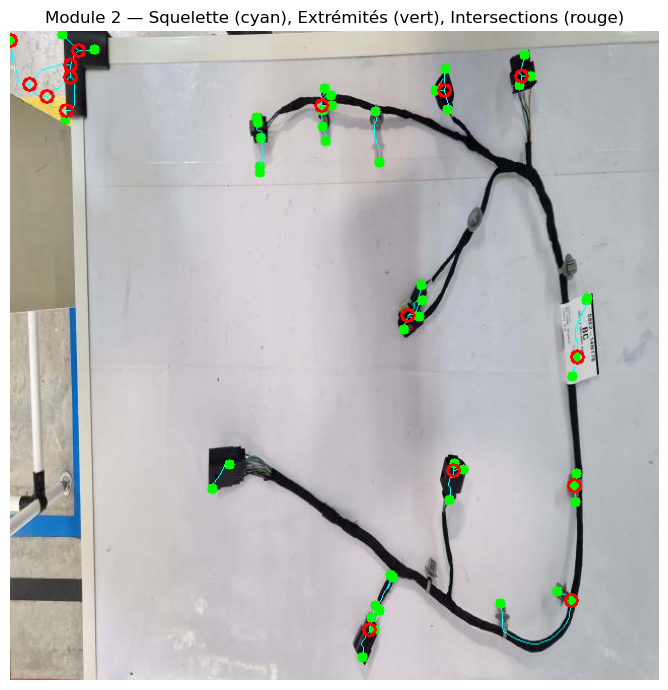

In [3]:
def cluster_points(pts_xy: list[tuple[int, int]], min_dist: float = 8.0) -> list[tuple[int, int]]:
    clusters = []
    for x, y in pts_xy:
        placed = False
        for c in clusters:
            cx, cy, n = c
            if np.hypot(x - cx / n, y - cy / n) <= min_dist:
                c[0] += x
                c[1] += y
                c[2] += 1
                placed = True
                break
        if not placed:
            clusters.append([float(x), float(y), 1])
    return [(int(round(cx / n)), int(round(cy / n))) for cx, cy, n in clusters]

kernel = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]], dtype=np.uint8)
vis_geom = img_bgr.copy()
geom_table = []

for det in detections:
    mask_u8 = det["mask_u8"]
    if int((mask_u8 > 0).sum()) == 0:
        continue
    clean = cv2.morphologyEx(mask_u8, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    skel = skeletonize(clean > 0).astype(np.uint8)
    coords_yx = np.argwhere(skel > 0)
    if len(coords_yx) == 0:
        continue

    neigh = cv2.filter2D(skel, ddepth=cv2.CV_16S, kernel=kernel)
    active_n = neigh[skel > 0]

    endpoints = cluster_points([(int(x), int(y)) for y, x in coords_yx[active_n == 1]], min_dist=8.0)
    branches = cluster_points([(int(x), int(y)) for y, x in coords_yx[active_n >= 3]], min_dist=8.0)

    vis_geom[skel > 0] = (255, 255, 0)  # Squelette en cyan
    for ex, ey in endpoints:
        cv2.circle(vis_geom, (ex, ey), 5, (0, 255, 0), -1)  # Extrémités en vert
    for bx, by in branches:
        cv2.circle(vis_geom, (bx, by), 6, (0, 0, 255), 2)  # Intersections en rouge

    geom_table.append({
        "id": det["id"],
        "class_name": det["class_name"],
        "conf": det["conf"],
        "length_px": int(len(coords_yx)),
        "nb_endpoints": len(endpoints),
        "nb_branches": len(branches),
    })

if geom_table:
    display(pd.DataFrame(geom_table))
else:
    print("Aucun masque exploitable pour le squelette sur cette image.")

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(vis_geom, cv2.COLOR_BGR2RGB))
plt.title("Module 2 — Squelette (cyan), Extrémités (vert), Intersections (rouge)")
plt.axis("off")
plt.tight_layout()
plt.show()